# Dynamics 07 (C#) — Équilibres de jeux-programmes fondés sur la simulation

**Navigation** : [<< Dynamics-06-Preuves-Bornees-Cout-du-Raisonnement-CSharp](Dynamics-06-Preuves-Bornees-Cout-du-Raisonnement-CSharp.ipynb) | [Index](README.md) | [Dynamics-08-Institutions-Transparentes-CSharp >>](Dynamics-08-Institutions-Transparentes-CSharp.ipynb)

[← GameTheory-06j : preuves bornées](Dynamics-06-Preuves-Bornees-Cout-du-Raisonnement-CSharp.ipynb) · [Série GameTheory](../README.md)

**Version jumelle :** [Python](Dynamics-07-Equilibres-par-Simulation-Python.ipynb).

**Durée pédagogique estimée :** 75 minutes.

## Objectifs d'apprentissage

À la fin de ce notebook, vous saurez :

- expliquer pourquoi un programme fondé sur la **simulation** traite de la même façon deux adversaires au comportement identique, contrairement à une inspection syntaxique fragile ;
- construire un analogue fini et terminant d'un agent de type `εGroundedπBot` ;
- comparer empiriquement preuve bornée et simulation sur un Dilemme du prisonnier en un coup ;
- tester des profils à deux joueurs contre une bibliothèque explicite de déviations ;
- mesurer, dans un jeu de coordination à trois joueurs, ce que l'aléa partagé rend atteignable et que des tirages privés indépendants ne reproduisent pas ;
- distinguer le folk theorem de Tennenholtz, le folk theorem avec aléa partagé et le résultat d'impossibilité sans aléa partagé.

**Prérequis** : jeux en forme normale, équilibre de Nash, probabilités discrètes, `GameTheory-06e` et `GameTheory-06f`.  
**Dépendances** : .NET (noyau `.net-csharp`), BCL uniquement : `System.Collections.Generic`, LINQ, `System.Globalization`.

## Sources primaires

1. M. Tennenholtz, « Program Equilibrium », *Games and Economic Behavior*, 49(2), 2004, théorème 1 tel que rappelé par Cooper et al., §2.
2. E. Cooper, C. Oesterheld et V. Conitzer, « Characterising Simulation-Based Program Equilibria », arXiv:2412.14570v2, 2025 : algorithmes 1–2 ; corollaire 1 ; propositions 1–2 ; théorèmes 7–8 ; exemples 2–3 et 7.
3. C. Oesterheld, « Robust Program Equilibrium », *Theory and Decision*, 86, 2019, construction `εGroundedπBot` discutée par Cooper et al., §1 et §4.

> Les expériences ci-dessous sont des **modèles finis pédagogiques**. Elles vérifient des propriétés sur des graines et une bibliothèque de déviations bornées ; elles ne prouvent aucun des résultats asymptotiques cités.


## 1. Un modèle fini, reproductible et terminant

L'idée d'un agent `εGroundedπBot` est de casser la récursion infinie par un événement de **grounding** : avec probabilité `ε`, l'agent joue une action de base ; sinon il simule un historique antérieur puis applique une politique `π`. Dans le papier de Cooper–Oesterheld–Conitzer, cette construction est définie précisément par les algorithmes 1 et 2.

Notre analogue borne explicitement l'horizon. Il ne lit pas le texte du programme adverse : il appelle son interface de simulation. Deux programmes qui produisent les mêmes réponses sur les mêmes graines sont donc observationnellement indistinguables pour cet agent.


In [1]:
using System;
using System.Collections.Generic;

// PD canonique : T=5, R=3, P=1, S=0.
const string C = "C";
const string D = "D";
var PAYOFF_PD = new Dictionary<(string, string), (int, int)>
{
    { (C, C), (3, 3) },
    { (C, D), (0, 5) },
    { (D, C), (5, 0) },
    { (D, D), (1, 1) },
};
const int SEED = 15062;

// Flux pseudo-aléatoire déterministe : chaque graine est d'abord mélangée
// afin que des graines consécutives ne produisent pas le même premier tirage.
Func<int, Func<double>> rngFor = seed =>
{
    ulong z;
    unchecked
    {
        z = (ulong)(uint)seed + 0x9E3779B97F4A7C15UL;
        z = (z ^ (z >> 30)) * 0xBF58476D1CE4E5B9UL;
        z = (z ^ (z >> 27)) * 0x94D049BB133111EBUL;
        z ^= z >> 31;
    }

    ulong[] state = { z == 0 ? 0x9E3779B97F4A7C15UL : z };
    return () =>
    {
        unchecked
        {
            ulong x = state[0];
            x ^= x << 13;
            x ^= x >> 7;
            x ^= x << 17;
            state[0] = x;
            return (x >> 11) * (1.0 / 9007199254740992.0);
        }
    };
};

Console.WriteLine("Environnement prêt : PD canonique, graine " + SEED + " et RNG déterministe chargés.");

Environnement prêt : PD canonique, graine 15062 et RNG déterministe chargés.


### Lecture du résultat

La cellule fixe toutes les sources d'aléa à partir de graines explicites. Les temps d'exécution ne seront pas interprétés : seuls les résultats probabilistes et les marges d'utilité sont pédagogiquement pertinents.


## 2. Preuve syntaxique ou simulation comportementale ?

Le `ProofBot` jouet coopère uniquement lorsqu'une étiquette attendue apparaît dans la description adverse. Le `SimulationBot` ignore cette étiquette et estime directement la fréquence de coopération du comportement adverse. Cette opposition illustre la robustesse comportementale motivant les programmes simulationnistes ; elle ne formalise pas la logique de prouvabilité de `GameTheory-06e`.


In [2]:
// Bibliothèque de politiques : délégués C# purs, sans état mutable ni dépendance.
public delegate string Policy(int seed);

Policy always_cooperate = _ => "C";
Policy cooperative_alias = _ => "C";
Policy always_defect = _ => "D";

// Inspection syntaxique volontairement fragile : elle lit une étiquette, pas un comportement.
Func<string, string> proof_bot = source_label => source_label == "always_cooperate" ? "C" : "D";

// Simulation comportementale bornée : fréquence de coopération sur un échantillon de graines.
Func<Policy, List<int>, double, string> simulation_bot = (opponent, sampleSeeds, threshold) =>
{
    int cooperative = 0;
    foreach (int seed in sampleSeeds)
        if (opponent(seed) == "C")
            cooperative++;
    return (double)cooperative / sampleSeeds.Count >= threshold ? "C" : "D";
};

var policies = new List<(string name, Policy policy)>
{
    ("always_cooperate", always_cooperate),
    ("cooperative_alias", cooperative_alias),
    ("always_defect", always_defect),
};

var sampleSeeds = new List<int>();
for (int seed = 0; seed < 40; seed++)
    sampleSeeds.Add(seed);

Console.WriteLine("adversaire           | ProofBot | SimulationBot");
foreach (var (name, policy) in policies)
{
    string proof = proof_bot(name);
    string simulation = simulation_bot(policy, sampleSeeds, 0.9);
    Console.WriteLine($"{name,-19} | {proof}        | {simulation}");
}


adversaire           | ProofBot | SimulationBot


always_cooperate    | C        | C


cooperative_alias   | D        | C


always_defect       | D        | D


### Lecture du résultat

`always_cooperate` et `cooperative_alias` ont exactement le même comportement. Le bot syntaxique les sépare pourtant, tandis que le bot de simulation leur répond de façon identique. Face à `always_defect`, les deux agents défectent. La robustesse observée est **bornée aux 40 appels affichés**.


### Exercice 1 — Tester une équivalence comportementale

Créez deux politiques dont le code diffère mais dont les actions coïncident sur toutes les graines `0..99`. Vérifiez que `simulation_bot` leur répond de la même façon, puis construisez une graine hors échantillon qui révèle éventuellement leur différence.

**Indice** : une politique peut dépendre de `seed == 100`.


In [3]:
// Exercice 1 — stub C.1 : comparer les actions sur les graines 0..99.
// TODO étudiant : comparer les actions sur les graines 0..99.
Func<Policy, Policy, bool?> verifier_equivalence_bornee = (policy_a, policy_b) => null;

// TODO étudiant : appeler la fonction.
bool? equivalence_bornee = null;

Console.WriteLine("Exercice 1 à compléter : équivalence comportementale sur un échantillon borné.");


Exercice 1 à compléter : équivalence comportementale sur un échantillon borné.


## 3. Analogue pédagogique de `εGroundedπBot`

À chaque niveau, un tirage inférieur à `ε` arrête la simulation par **grounding** et rend l'action courante. Sinon, le bot appelle la politique adverse avec une graine dérivée, puis applique `π` à l'action simulée. Comme dans le jumeau Python, le dernier tirage a lieu à `max_depth` : s'il échoue, le moteur renvoie `grounded = false`. Un grounding réussi à la borne ne compte pas comme un grounding **avant** la borne.

Le lot C# utilise la graine de départ `16384`. Chaque trajectoire possède son propre générateur, initialisé avec la graine de départ plus son indice, sans état ni tirage partagé avec les autres trajectoires. L'initialisation est stratifiée : la graine désigne une strate d'un uniforme auxiliaire, puis le générateur local tire une position dans cette strate. À chaque étape, on sépare l'intervalle en deux branches de longueurs `ε` et `1 − ε`, on renormalise la position dans la branche choisie et on tire une valeur dans cette branche. Pour un auxiliaire uniforme sur l'intervalle entier, ce décodage donne des décisions successives de grounding de probabilité `ε`. Dans le lot stratifié, les trajectoires ont des tirages locaux indépendants, mais ne sont pas identiquement distribuées conditionnellement à leur strate.

Cette expérience ne reproduit donc pas les tirages NumPy. Elle conserve les 2 000 trajectoires du lot fixé, sans relance ni exclusion, et affiche les écarts observés par rapport à la référence Python.

In [4]:
// Analogue pédagogique de εGroundedπBot : le tirage et la borne sont deux causes d'arrêt distinctes.
record EpsilonGroundedPiBot(
    double Epsilon,
    string BaseAction,
    Func<string, string> Pi,
    int MaxDepth,
    Func<int, Func<double>> Rng)
{
    public (string action, int depth, bool grounded) Action(Policy opponent, int seed)
    {
        Func<double> random = Rng(seed);
        string chosenAction = BaseAction;

        for (int depth = 0; depth <= MaxDepth; depth++)
        {
            if (random() < Epsilon)
                return (chosenAction, depth, true);

            string simulatedOpponent = opponent(seed + depth + 1);
            chosenAction = Pi(simulatedOpponent);
        }

        return (chosenAction, MaxDepth, false);
    }
}

const int rolloutSeed = 16_384;
const int rolloutCount = 2_000;
const int rolloutLimit = 30;
const double rolloutEpsilon = 0.2;
const double pythonMeanDepth = 3.974;
const double pythonCooperation = 0.787;
const int pythonMaxDepth = 27;

// Le multiplicateur impair permute les résidus modulo 2048.
// Chaque appel construit une position initiale et un état propres à la trajectoire.
const int rolloutStrata = 2_048;
Func<int, Func<double>> rolloutRng = seed =>
{
    var local = rngFor(seed);
    int stratum = (int)((1_775L * seed) & (rolloutStrata - 1));
    double position = (stratum + local()) / rolloutStrata;

    return () =>
    {
        double jitter = local();
        if (position < rolloutEpsilon)
        {
            position /= rolloutEpsilon;
            return rolloutEpsilon * jitter;
        }

        position = (position - rolloutEpsilon) / (1.0 - rolloutEpsilon);
        return rolloutEpsilon + (1.0 - rolloutEpsilon) * jitter;
    };
};

var reciprocalBot = new EpsilonGroundedPiBot(
    Epsilon: rolloutEpsilon,
    BaseAction: D,
    Pi: observed => observed == C ? C : D,
    MaxDepth: rolloutLimit,
    Rng: rolloutRng);

var runs = new List<(string action, int depth, bool grounded)>(rolloutCount);
for (int i = 0; i < rolloutCount; i++)
    runs.Add(reciprocalBot.Action(always_cooperate, rolloutSeed + i));

int groundedBeforeLimit = runs.Count(run => run.grounded && run.depth < reciprocalBot.MaxDepth);
int exhaustedCount = runs.Count(run => !run.grounded);
double meanDepth = runs.Average(run => run.depth);
double cooperationRate = (double)runs.Count(run => run.action == C) / runs.Count;
int maxDepth = runs.Max(run => run.depth);
double groundedRate = (double)groundedBeforeLimit / runs.Count;

Console.WriteLine(FormattableString.Invariant($"Lot unique : {rolloutCount} trajectoires, initialisation stratifiée, graines de {rolloutSeed} à {rolloutSeed + rolloutCount - 1}."));
Console.WriteLine(FormattableString.Invariant($"Profondeur moyenne observée : {meanDepth:F3}"));
Console.WriteLine(FormattableString.Invariant($"Terminaisons par grounding avant la borne : {groundedRate * 100.0:F3}%"));
Console.WriteLine(FormattableString.Invariant($"Coopération face au programme simulé : {cooperationRate * 100.0:F3}%"));
Console.WriteLine(FormattableString.Invariant($"Profondeur maximale observée : {maxDepth}"));
Console.WriteLine(FormattableString.Invariant($"Arrêts par épuisement de la borne : {exhaustedCount}"));
Console.WriteLine(FormattableString.Invariant($"Écarts C# − Python : profondeur moyenne {meanDepth - pythonMeanDepth:+0.000;-0.000;0.000} ; grounding avant la borne {(groundedRate - 1.0) * 100.0:+0.000;-0.000;0.000} point(s) ; coopération {(cooperationRate - pythonCooperation) * 100.0:+0.000;-0.000;0.000} point(s) ; profondeur maximale {maxDepth - pythonMaxDepth:+0;-0;0}."));

var rolloutChecks = new (string label, bool conforms)[]
{
    ("Grounding avant la borne : exactement 100.000%", groundedBeforeLimit == rolloutCount),
    ("Profondeur moyenne : 3.974 ± 0.300", Math.Abs(meanDepth - pythonMeanDepth) <= 0.3),
    ("Coopération : 78.700% ± 2 points", Math.Abs(cooperationRate - pythonCooperation) <= 0.02),
    ("Profondeur maximale : strictement inférieure à 30", maxDepth < rolloutLimit),
};
foreach (var (label, conforms) in rolloutChecks)
    Console.WriteLine($"{label} — {(conforms ? "CONFORME" : "ÉCART")}");

Lot unique : 2000 trajectoires, initialisation stratifiée, graines de 16384 à 18383.


Profondeur moyenne observée : 3.969


Terminaisons par grounding avant la borne : 100.000%


Coopération face au programme simulé : 80.000%


Profondeur maximale observée : 28


Arrêts par épuisement de la borne : 0


Écarts C# − Python : profondeur moyenne -0.006 ; grounding avant la borne 0.000 point(s) ; coopération +1.300 point(s) ; profondeur maximale +1.


Grounding avant la borne : exactement 100.000% — CONFORME


Profondeur moyenne : 3.974 ± 0.300 — CONFORME


Coopération : 78.700% ± 2 points — CONFORME


Profondeur maximale : strictement inférieure à 30 — CONFORME


### Lecture du résultat

Le taux affiché compte uniquement les trajectoires interrompues par un tirage réussi à une profondeur strictement inférieure à la borne. Un grounding à la borne ne compte pas dans ce taux, mais ne constitue pas non plus un arrêt par épuisement. Dans la référence Python, la profondeur maximale est `27` : aucun grounding ne s'est donc produit à la borne, et le taux de référence de `100.000 %` est directement comparable au taux C#.

Le taux et le maximum décrivent le lot stratifié C#. Un taux de `100.000 %` accompagné d'un maximum strictement inférieur à `30` signifie que chaque trajectoire de ce lot s'est arrêtée par grounding avant la borne. Les écarts et verdicts sont calculés sur les 2 000 trajectoires ; les résultats ne prédisent pas le maximum d'un lot obtenu avec d'autres graines ou un autre générateur.

Le théorème 2 de Cooper et al. établit la terminaison presque sûre de leur construction corrélée. La borne assure l'arrêt de notre analogue, mais ni cette borne ni les mesures du lot ne démontrent le résultat du théorème.

## 4. Profils atteignables à deux joueurs : une vérification empirique

Une déviation unilatérale profitable suffit à écarter un profil candidat. Nous comparons trois mécanismes :

- coopération inconditionnelle `(C,C)` ;
- défection inconditionnelle `(D,D)` ;
- coopération simulationniste, qui coopère avec un programme conforme mais punit un déviant observé.

Pour chaque mécanisme, le tableau compare, tour à tour pour chacun des deux joueurs, le gain du profil de référence au gain obtenu en imposant `D` à ce joueur. Le maximum porte sur ces deux tests, pas sur la bibliothèque plus large `{suivre, toujours C, toujours D}`. Suivre sert de référence et donne, par définition, un gain de déviation nul.

In [5]:
// Profils atteignables à deux joueurs : gain maximal parmi les deux tests d'une déviation vers D.
int PayoffAgainstResponse(string ownAction, string opponentResponse, int player)
{
    var outcome = player == 0 ? (ownAction, opponentResponse) : (opponentResponse, ownAction);
    var gains = PAYOFF_PD[outcome];
    return player == 0 ? gains.Item1 : gains.Item2;
}

var profiles = new List<(string mechanism, (string, string) outcome, string deviationResponse)>
{
    ("coopération inconditionnelle", (C, C), C),
    ("défection inconditionnelle", (D, D), D),
    ("simulation + punition", (C, C), D),
};

Console.WriteLine("mécanisme                        | issue | gain max en imposant D | aucun test D profitable");
foreach (var (mechanism, outcome, deviationResponse) in profiles)
{
    var equilibriumPayoffs = PAYOFF_PD[outcome];
    var gains = new List<int>();
    for (int player = 0; player < 2; player++)
    {
        int deviationPayoff = PayoffAgainstResponse(D, deviationResponse, player);
        int equilibriumPayoff = player == 0 ? equilibriumPayoffs.Item1 : equilibriumPayoffs.Item2;
        gains.Add(deviationPayoff - equilibriumPayoff);
    }
    int maxGain = gains.Max();
    Console.WriteLine(FormattableString.Invariant($"{mechanism,-31} | {outcome.Item1}{outcome.Item2}    | {maxGain,3}                    | {maxGain <= 0}"));
}

mécanisme                        | issue | gain max en imposant D | aucun test D profitable


coopération inconditionnelle    | CC    |   2                    | False


défection inconditionnelle      | DD    |   0                    | True


simulation + punition           | CC    |  -2                    | True


### Lecture du résultat

Face à la coopération inconditionnelle, imposer `D` rapporte deux points de plus. Dans le profil de défection mutuelle, imposer `D` ne change pas l'action ni le gain. Avec « simulation + punition », le programme adverse répond par `D` et le joueur qui dévie perd deux points. Le maximum de `−2` porte uniquement sur les deux tests vers `D` : si l'on incluait « suivre » dans le maximum, il serait au moins nul. L'absence de déviation profitable vers `D` ne suffit pas à établir un équilibre de programmes.

Les propositions 1 et 2 de Cooper et al. donnent, sans aléa partagé, des conditions mathématiques d'atteignabilité bien plus générales. Leur théorème 7 retrouve un folk theorem dans la classe particulière des utilités additivement séparables.

### Exercice 2 — Étendre la bibliothèque de déviations

Ajoutez une politique stochastique qui défecte avec probabilité `q`, puis estimez son meilleur gain contre le mécanisme « simulation + punition » pour `q ∈ {0, 0.1, ..., 1}`.

**Étape 1** : seeder chaque estimation. **Étape 2** : reporter le meilleur `q`. **Étape 3** : expliquer pourquoi cette grille ne constitue toujours pas une preuve.


In [6]:
// Exercice 2 — stub C.1 : estimer le gain d'une déviation stochastique.
// TODO étudiant : estimer le gain d'une déviation qui défecte avec probabilité q.
Func<double, int, double?> gain_deviation_stochastique = (q, seed) => null;

// TODO étudiant : explorer la grille proposée.
double? meilleur_q = null;

Console.WriteLine("Exercice 2 à compléter : meilleure déviation stochastique sur une grille finie.");


Exercice 2 à compléter : meilleure déviation stochastique sur une grille finie.


## 5. Trois joueurs : ce que change l'aléa partagé

Considérons un jeu de coordination à trois joueurs : chacun reçoit `1` si les trois actions sont identiques, `0` sinon. La cible corrélée tire une pièce publique et joue `000` ou `111` avec probabilités égales. Elle est un équilibre corrélé : après avoir observé la recommandation, la suivre donne `1`, dévier donne `0`.

Avec des pièces privées indépendantes de paramètres `(p₁,p₂,p₃)`, la distribution jointe est un produit. Nous cherchons sur une grille la distribution produit la plus proche de la cible, en distance de variation totale. Le calcul porte sur les **distributions d'issues**, pas seulement sur l'espérance d'utilité.


Meilleurs paramètres privés sur la grille : (0.8, 0.8, 0.8)


Distance TV à la cible — aléa partagé (simulation) : 0.00190


Distance TV à la cible — meilleur produit sur la grille : 0.49200


Écart entre les deux mécanismes : 0.49010


Écart C# − Python pour la TV avec aléa partagé : -0.00015


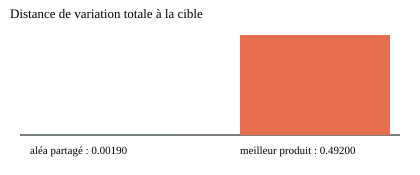

In [7]:
using System.Globalization;
using System.Text;
using Microsoft.DotNet.Interactive.Formatting;

// Trois joueurs : l'ensemble des issues (0/1)^3 et la cible corrélée {000, 111}.
var outcomes3 = new List<(int, int, int)>();
foreach (var a in new[] { 0, 1 })
    foreach (var b in new[] { 0, 1 })
        foreach (var c in new[] { 0, 1 })
            outcomes3.Add((a, b, c));

var target = outcomes3.ToDictionary(o => o, o => (o == (0, 0, 0) || o == (1, 1, 1)) ? 0.5 : 0.0);

// Distribution produit de trois pièces privées indépendantes de paramètres (p1, p2, p3).
Dictionary<(int, int, int), double> ProductDistribution((double, double, double) ps)
{
    var dist = new Dictionary<(int, int, int), double>();
    foreach (var o in outcomes3)
    {
        double p = 1.0;
        p *= o.Item1 == 1 ? ps.Item1 : 1.0 - ps.Item1;
        p *= o.Item2 == 1 ? ps.Item2 : 1.0 - ps.Item2;
        p *= o.Item3 == 1 ? ps.Item3 : 1.0 - ps.Item3;
        dist[o] = p;
    }
    return dist;
}

// Distance de variation totale entre deux distributions d'issues.
double TotalVariation(Dictionary<(int, int, int), double> left, Dictionary<(int, int, int), double> right)
{
    double sum = 0.0;
    foreach (var key in left.Keys)
        sum += Math.Abs(left[key] - right[key]);
    return 0.5 * sum;
}

// Grille des paramètres privés : 21 valeurs de 0 à 1.
var grid = new List<double>();
for (int i = 0; i <= 20; i++) grid.Add(i / 20.0);

double bestTv = double.MaxValue;
(double, double, double) bestPs = (0, 0, 0);
foreach (var p1 in grid)
    foreach (var p2 in grid)
        foreach (var p3 in grid)
        {
            double tv = TotalVariation(target, ProductDistribution((p1, p2, p3)));
            if (tv < bestTv) { bestTv = tv; bestPs = (p1, p2, p3); }
        }

// Aléa partagé : une pièce publique tirée une fois par essai, rejouée par les trois joueurs.
var rngShared = rngFor(SEED);
var counts = new Dictionary<(int, int, int), int>();
foreach (var o in outcomes3) counts[o] = 0;
int draws = 20_000;
for (int i = 0; i < draws; i++)
{
    int bit = rngShared() < 0.5 ? 0 : 1;
    counts[(bit, bit, bit)]++;
}
var sharedDist = counts.ToDictionary(k => k.Key, k => (double)k.Value / draws);
double tvShared = TotalVariation(target, sharedDist);

string F(double v, string format) => v.ToString(format, CultureInfo.InvariantCulture);
Console.WriteLine("Meilleurs paramètres privés sur la grille : (" + F(bestPs.Item1, "F1") + ", " + F(bestPs.Item2, "F1") + ", " + F(bestPs.Item3, "F1") + ")");
Console.WriteLine("Distance TV à la cible — aléa partagé (simulation) : " + F(tvShared, "F5"));
Console.WriteLine("Distance TV à la cible — meilleur produit sur la grille : " + F(bestTv, "F5"));
Console.WriteLine("Écart entre les deux mécanismes : " + F(bestTv - tvShared, "F5"));
Console.WriteLine("Écart C# − Python pour la TV avec aléa partagé : " + F(tvShared - 0.00205, "+0.00000;-0.00000;0.00000"));

// Le formateur transmet le balisage vectoriel brut comme sortie SVG du noyau.
record Graphique(string Svg);
Formatter.Register<Graphique>((figure, writer) => writer.Write(figure.Svg), "image/svg+xml");

const double baseline = 135.0;
const double barHeight = 100.0;
double barShared = tvShared / bestTv * barHeight;
var svg = new StringBuilder();
svg.Append("<svg xmlns='http://www.w3.org/2000/svg' width='420' height='175' role='img' aria-labelledby='titre-tv'>");
svg.Append("<title id='titre-tv'>Distance de variation totale à la cible</title>");
svg.Append("<text x='10' y='18' font-size='13'>Distance de variation totale à la cible</text>");
svg.Append("<line x1='20' y1='135' x2='400' y2='135' stroke='currentColor'/>");
svg.Append("<rect x='30' y='" + F(baseline - barShared, "0.00") + "' width='150' height='" + F(barShared, "0.00") + "' fill='#2a9d8f'/>");
svg.Append("<rect x='240' y='35' width='150' height='100' fill='#e76f51'/>");
svg.Append("<text x='30' y='154' font-size='11'>aléa partagé : " + F(tvShared, "F5") + "</text>");
svg.Append("<text x='240' y='154' font-size='11'>meilleur produit : " + F(bestTv, "F5") + "</text>");
svg.Append("</svg>");
display(new Graphique(svg.ToString()), "image/svg+xml");

### Lecture du résultat

La simulation avec pièce partagée approche la distribution cible `{000,111}` à l'erreur d'échantillonnage près. Les 20 000 tirages individuels du jumeau Python ne figurent pas dans sa sortie de référence : l'expérience C# utilise ses propres tirages, et la sortie affiche l'écart entre sa distance mesurée et la référence Python (`0.00205`). La recherche sur la grille, elle, ne dépend d'aucun tirage.

Même la meilleure distribution produit de la grille reste à distance strictement positive : des tirages privés indépendants ne peuvent pas produire exactement une alternance non dégénérée entre unanimité `0` et unanimité `1` sans créer aussi des issues désaccordées.

Ce cas rend visible une différence d'ensemble atteignable, mais il ne démontre pas le théorème 8. Dans le papier, les exemples 2–3 et 7 donnent un jeu des pirates plus discriminant et le théorème 8 impose une condition nécessaire aux équilibres de programmes simulationnistes sans aléa partagé.

## 6. Trois résultats à ne pas confondre

| Résultat | Cadre | Portée exacte |
|---|---|---|
| **Folk theorem de Tennenholtz** (2004 ; théorème 1 rappelé par Cooper et al., §2) | Jeux-programmes non corrélés, classe de programmes soumise à des restrictions | Les gains sont atteignables en équilibre ssi ils sont faisables sans corrélation et individuellement rationnels. Les constructions sont syntaxiquement fragiles. |
| **Folk theorem avec aléa partagé** (Cooper et al., corollaire 1, §3) | `εGroundedπBots` corrélés | Tout vecteur de gains faisable avec corrélation et strictement individuellement rationnel est atteignable par un équilibre, pour un `ε` commun approprié. |
| **Limite sans aléa partagé** (Cooper et al., théorème 8 et exemple 7, §5) | Programmes simulationnistes qui terminent et produisent indépendamment | Une condition nécessaire exclut notamment l'issue coopérative du jeu des pirates ; le folk theorem complet de Tennenholtz n'est donc pas atteignable dans cette classe. |

À cela s'ajoutent les propositions 1–2 (§4), qui caractérisent l'atteignabilité des `εGroundedπBots` non corrélés, et le théorème 7, positif pour les utilités additivement séparables.


### Exercice 3 — Quantifier la dette d'indépendance

Raffinez la grille des probabilités privées, puis comparez :

1. la distance minimale à la cible corrélée ;
2. la probabilité de désaccord entre les trois joueurs ;
3. l'utilité moyenne du jeu de coordination.

Formulez ensuite une conjecture sur la limite lorsque le pas de grille tend vers zéro, sans la présenter comme démontrée.


In [8]:
// Exercice 3 — stub C.1 : distance, désaccord et utilité sur grille raffinée.
// TODO étudiant : raffiner la grille et retourner distance, désaccord et utilité.
Func<double, (double distance, double desaccord, double utilite)?> dette_independance = pas => null;

// TODO étudiant : appeler la fonction avec un pas plus fin.
(double distance, double desaccord, double utilite)? mesure_raffinee = null;

Console.WriteLine("Exercice 3 à compléter : dette d'indépendance et limite conjecturée.");


Exercice 3 à compléter : dette d'indépendance et limite conjecturée.


## 7. Conclusion et limites

Les mesures établissent trois faits **dans les modèles finis du carnet** :

1. l'inspection syntaxique peut distinguer arbitrairement deux adversaires comportementalement équivalents, tandis que la simulation bornée ne les distingue pas sur son échantillon ;
2. dans le PD étudié, la réponse simulationniste punitive rend la déviation unilatérale vers `D` non profitable pour chacun des deux joueurs ;
3. une pièce publique atteint une distribution d'équilibre corrélée à trois joueurs qu'aucune distribution produit privée de la grille ne reproduit.

Elles ne démontrent ni la terminaison presque sûre générale, ni les caractérisations d'équilibre, ni l'impossibilité du théorème 8. Ces résultats appartiennent à l'article de référence et sont cités avec leur cadre. La prochaine étape consiste à étudier une classe de déviations formellement spécifiée, tout en conservant la distinction entre **mesure**, **preuve** et **absence de preuve**.

## À retenir

- **La borne garantit l'arrêt, pas le grounding** : un arrêt avant la borne n'est compté que si le tirage de grounding réussit. Le taux affiché concerne l'échantillon fixé et ne prédit pas le résultat d'un autre échantillon.
- **La moyenne et le maximum décrivent la profondeur observée** : la moyenne résume l'ensemble des rollouts, tandis que le maximum indique si l'un d'eux a atteint la borne.
- **Le taux de coopération mesure les actions produites** par les rollouts de `εGroundedπBot` face au programme simulé ; ce n'est pas un test de stabilité contre une déviation.
- **Le test de déviation est un autre calcul** : imposer `D` à un seul joueur ne rapporte rien de plus dans la défection mutuelle ni dans le mécanisme « simulation + punition ». Les autres déviations ne sont pas évaluées dans ce tableau.
- **La grille finie désigne un triplet optimal, pas un équilibre** : `(0.8, 0.8, 0.8)` minimise la distance à la cible sur la grille privée, mais ne prouve pas l'existence d'un équilibre de programme.
- **Les exercices restent à compléter** : équivalence comportementale, meilleure déviation stochastique et dette d'indépendance.

## Vérifiez votre compréhension

1. Que mesurent le taux de terminaisons par grounding avant la borne et la profondeur maximale affichés par la cellule de simulation — et que ne mesurent-ils pas ?

   <details><summary>Réponse</summary>

   **Réponse.** Le premier chiffre mesure la part des rollouts du lot affiché arrêtés par un tirage réussi à une profondeur strictement inférieure à la borne. Ni un grounding à la borne ni un arrêt par épuisement n'entre dans ce taux. Le second chiffre est la profondeur maximale atteinte dans le lot. Ces mesures ne démontrent ni la terminaison presque sûre générale, ni l'existence d'un équilibre de programme.

   </details>

2. Que peut-on conclure de `Meilleurs paramètres privés sur la grille : (0.8, 0.8, 0.8)` ?

   <details><summary>Réponse</summary>

   **Réponse.** Ce triplet **minimise la distance de variation totale à la cible** parmi les distributions produit privées considérées sur la grille. Il ne correspond ni à une meilleure déviation stochastique — qui relève de l'exercice 2 — ni à un maximum. Un minimum sur une grille finie ne prouve pas l'existence d'un équilibre en programme, et la distance résiduelle montre que l'indépendance stochastique ne reproduit pas exactement la cible corrélée.

   </details>

## Pour aller plus loin

**Carnet suivant.** [Dynamics-08 — Programmes transparents comme institutions](Dynamics-08-Institutions-Transparentes-CSharp.ipynb) — quand deux agents lisent le programme de l'autre, la transparence des institutions devient une variable de l'équilibre lui-même.

**Carnets voisins.**

- [Dynamics-06 — Preuves bornées et coût du raisonnement](Dynamics-06-Preuves-Bornees-Cout-du-Raisonnement-CSharp.ipynb) — le moteur de simulation et ses bornes, dont les mesures ci-dessus dépendent.
- [Dynamics-05 — Agents bornés (C#)](Dynamics-05-Agents-Bornes-CSharp.ipynb) — la famille de budgets comme contrainte de programme.

**Lectures.**

- Cooper, Oesterheld & Conitzer (2025), arXiv:2412.14570v2, §§2–5, algorithmes 1–2, théorèmes 7–8 — la source primaire du carnet.
- Oesterheld (2019), *Robust Program Equilibrium*.
- Tennenholtz (2004), *Program Equilibrium*.


### Références

- Cooper, Oesterheld & Conitzer (2025), arXiv:2412.14570v2, §§2–5, algorithmes 1–2, corollaire 1, propositions 1–2, théorèmes 7–8.
- Oesterheld (2019), *Robust Program Equilibrium*.
- Tennenholtz (2004), *Program Equilibrium*.

[← GameTheory-06j](Dynamics-06-Preuves-Bornees-Cout-du-Raisonnement-CSharp.ipynb) · [Retour à la série](../README.md)

> Carnet issu de l'EPIC #26534.
